# Experiment 13: Blood Cell Classification Using Convolutional Neural Network (CNN)

## Aim
To design and train a Convolutional Neural Network (CNN) for classifying different types of blood cells from microscopic images.

In [13]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"   # Force CPU mode

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("Running on CPU")

TensorFlow version: 2.20.0
Running on CPU


In [14]:
import os

INPUT_DIR = "/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset"

print("Available dataset folders:")

for root, dirs, files in os.walk(INPUT_DIR):
    level = root.replace(INPUT_DIR, "").count(os.sep)

    if level <= 4:
        print(root)

Available dataset folders:
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset/monocyte
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset/ig
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset/neutrophil
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset/basophil
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset/lymphocyte
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset/erythroblast
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset/eosinophil
/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset/platelet


In [15]:
import os
import tensorflow as tf

INPUT_DIR = "/kaggle/input"

required_classes = {
    "EOSINOPHIL",
    "LYMPHOCYTE",
    "MONOCYTE",
    "NEUTROPHIL"
}

DATA_DIR = None

for root, dirs, files in os.walk(INPUT_DIR):
    if required_classes.issubset({d.upper() for d in dirs}):
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Class folders not found. Run Cell 2 and check the dataset structure."
    )

print("Dataset directory:", DATA_DIR)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# -------------------------------------------------
# STEP 1: 80% Training + 20% temporary dataset
# -------------------------------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# Save class names BEFORE modifying datasets
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("\nClasses:", class_names)
print("Number of classes:", NUM_CLASSES)

# -------------------------------------------------
# STEP 2: Split remaining 20% into
#         10% Validation + 10% Test
# -------------------------------------------------

temp_batches = tf.data.experimental.cardinality(temp_ds).numpy()

val_batches = temp_batches // 2

val_ds = temp_ds.take(val_batches)
test_ds = temp_ds.skip(val_batches)

# -------------------------------------------------
# Performance optimization
# -------------------------------------------------

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("\nDataset split completed successfully.")
print("Training dataset: Ready")
print("Validation dataset: Ready")
print("Test dataset: Ready")

Dataset directory: /kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset
Found 17092 files belonging to 8 classes.
Using 13674 files for training.
Found 17092 files belonging to 8 classes.
Using 3418 files for validation.

Classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Number of classes: 8

Dataset split completed successfully.
Training dataset: Ready
Validation dataset: Ready
Test dataset: Ready


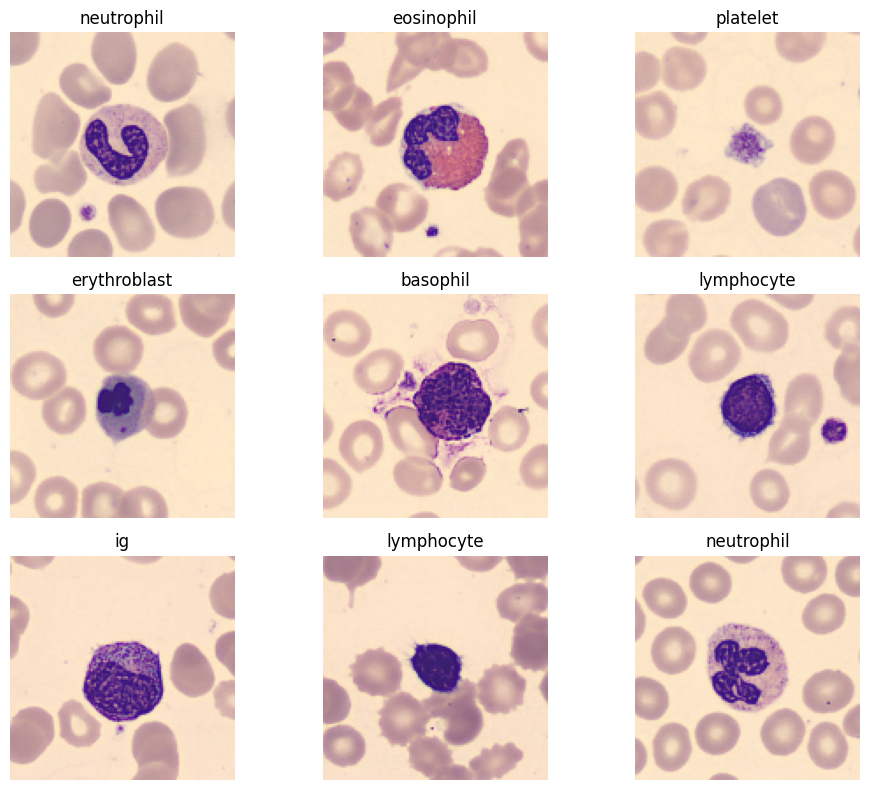

In [16]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Normalize image pixels
    layers.Rescaling(1.0 / 255),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,712 (16.36 MB)

 Trainable params: 4,288,712 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_blood_cell_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 224s 520ms/step - accuracy: 0.4950 - loss: 1.2976 - val_accuracy: 0.7075 - val_loss: 0.7743
Epoch 2/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 224s 523ms/step - accuracy: 0.6920 - loss: 0.7961 - val_accuracy: 0.8019 - val_loss: 0.5052
Epoch 3/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 224s 522ms/step - accuracy: 0.7483 - loss: 0.6481 - val_accuracy: 0.8219 - val_loss: 0.4870
Epoch 4/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 223s 522ms/step - accuracy: 0.7733 - loss: 0.5805 - val_accuracy: 0.8526 - val_loss: 0.3996
Epoch 5/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 223s 521ms/step - accuracy: 0.8069 - loss: 0.5001 - val_accuracy: 0.8968 - val_loss: 0.3365
Epoch 6/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 223s 522ms/step - accuracy: 0.8365 - loss: 0.4333 - val_accuracy: 0.8992 - val_loss: 0.3025
Epoch 7/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 224s 524ms/step - accuracy: 0.8559 - loss: 0.3841 - val_accuracy: 0.9116 - val_loss: 0.2782
Epoch 8/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 227s 531ms/step - accuracy: 0.8700 -

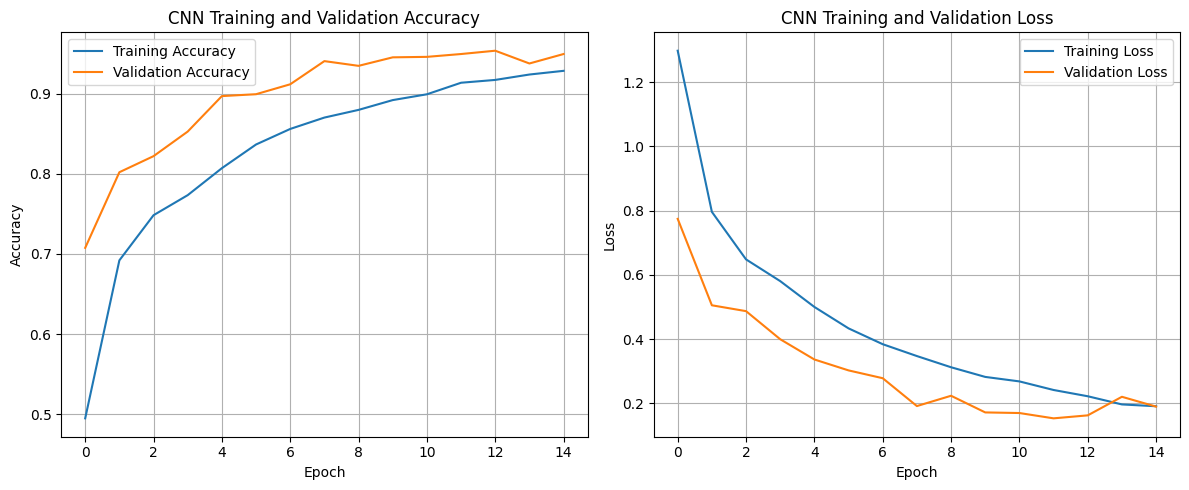

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [20]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy: {:.2f}%".format(test_accuracy * 100))

54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 156ms/step - accuracy: 0.9477 - loss: 0.1397
Test Loss: 0.1397
Test Accuracy: 94.77%


In [25]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

    basophil       0.98      0.94      0.96       111
  eosinophil       0.99      0.99      0.99       322
erythroblast       0.98      0.94      0.96       170
          ig       0.81      0.93      0.87       300
  lymphocyte       0.95      0.98      0.96       107
    monocyte       0.91      0.85      0.88       151
  neutrophil       0.98      0.91      0.94       344
    platelet       1.00      1.00      1.00       217

    accuracy                           0.94      1722
   macro avg       0.95      0.94      0.94      1722
weighted avg       0.95      0.94      0.94      1722



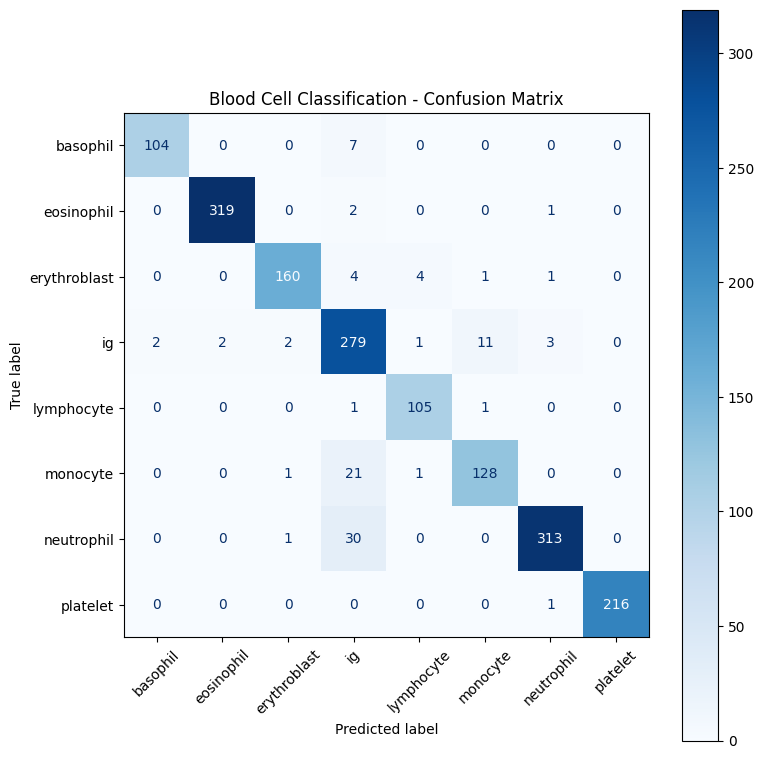

In [26]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Blood Cell Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

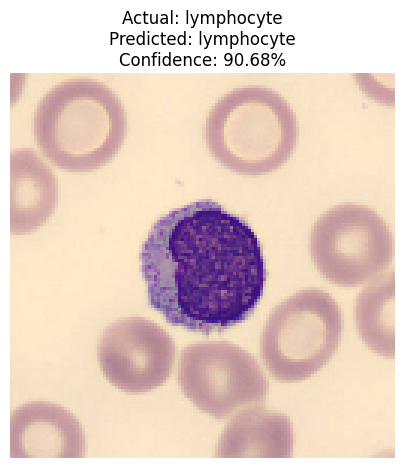

Actual class: lymphocyte
Predicted class: lymphocyte


In [27]:
# Get one batch of test images
for images, labels in test_ds.take(1):
    sample_image = images[0]
    actual_label = int(labels[0])
    break

prediction = model.predict(
    tf.expand_dims(sample_image, axis=0),
    verbose=0
)[0]

predicted_label = int(np.argmax(prediction))

plt.figure(figsize=(5, 5))
plt.imshow(sample_image.numpy().astype("uint8"))
plt.axis("off")
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}\n"
    f"Confidence: {prediction[predicted_label] * 100:.2f}%"
)
plt.show()

print("Actual class:", class_names[actual_label])
print("Predicted class:", class_names[predicted_label])

In [28]:
# Save trained model
model.save("/kaggle/working/blood_cell_cnn.keras")

# Save training history
pd.DataFrame(history.history).to_csv(
    "/kaggle/working/training_history.csv",
    index=False
)

# Save classification report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "/kaggle/working/classification_report.csv"
)

print("All output files saved successfully.")

All output files saved successfully.
